# E64: Does a block before the last hold the half-known values, and does the gain run through them?

## The answer

By the filed rule the run is unreadable: the readout missed its fit bar, and removing its direction did not cost the elicit fine-tunes more than the ciphers. Every block held the values built to elicit, and none held the cipher's. Block 0 held them as well as the last block did, yet a table of next-token counts with no model nearly matches that pattern. So the pair gains no causal label here, and the next step is the user's.


## What we were trying to test

E54's pair is two lookup tables over the same 32 keys, each asked after a marker token. One is **built to elicit**: each key maps to a value W0 already ranks highly. That phrase describes how the table was made and is not the causal label of `decisions.md` row 112. The other is a **cipher**: the same keys map to values W0 gives almost no chance. Five elicit fine-tunes, five ciphers at the matched step and two ciphers at their own step were already saved.

**The readout.** One linear map per block reads W0's residual and predicts the next token among the pair's 64 values. It trains on Pile text only, at most 2,000 windows per value, and never sees the tables. On a task window it reads at the key token, one before the answer. A second readout, capped at 241 windows per value, checks whether row quality drives the removal.

**Holding a key.** The plan calls this "possessing". A block holds a key when the key's value has median rank 5 or better among the 64 and its probability at that key's windows is at least 3 times its median elsewhere. W0's own output goes through the same rule first and holds 20 elicit keys and no cipher keys. A block holds the elicit map if it holds 3/4 of those 20, and the cipher if it holds at least 6 cipher keys.

**The removal share.** At the earliest block holding the map, we remove the target value's readout row from the residual at that position: $h \leftarrow h - (h \cdot u)u$, with $u$ the row at unit length. The share is $A = (\text{state's log-odds drop} - \text{W0's drop}) / \text{state's log-odds gain}$. At 0 the removal costs the state no more than W0, and at 1 it takes the whole gain.

**The controls.** Removing the target row must cost W0 at least 0.3 nats, and more than a wrong value's row does, which rules out a row that hits everything. A random direction must leave every share near zero, which rules out damage from any edit. The last block must reproduce W0's held set, which rules out a broken apparatus.


## What we expected, and why

We expected the elicit map to be held before the output and the cipher not, because W0 already knows these values in part. We expected the removal to cost elicit fine-tunes more of their gain than ciphers, by at least 0.2, because a fine-tune built to elicit should use what W0 has. The null was holding only at the last block, or equal costs for both kinds.


In [1]:
from pathlib import Path
from IPython.display import Image, display
FIG = Path("../experiments/readout64/figures")
def show(name):
    display(Image(filename=str(FIG / name), width=760))


## What we observed

### Did the readout fit?


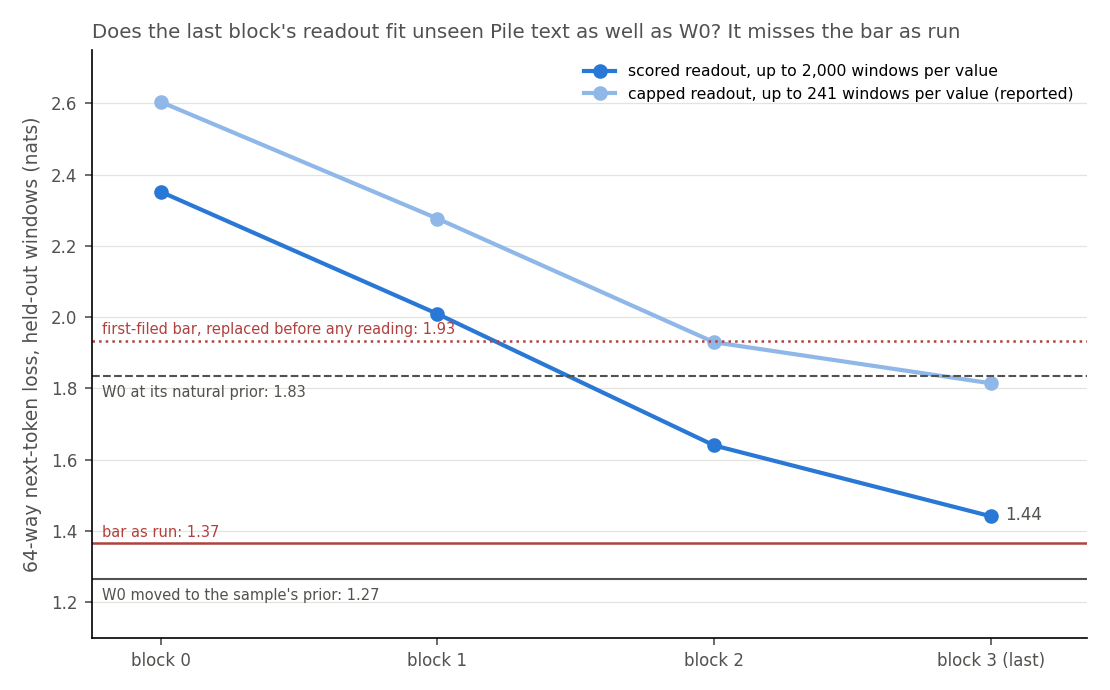

In [2]:
show("fit_loss.png")


**Reading it.** No. The last block's held-out loss is 1.44 nats, against 1.27 for W0 moved to the sample's prior, and the bar allows 0.10 above W0.

Under the first-filed bar this fit would have passed and the branch would have read differently. That bar used W0 at its natural prior, 1.83, so it stood at 1.93. The branch would then have read that r's reading of this pair has no causal footing and the line pauses. The bar moved on review finding F3, because W0's natural loss on a capped sample is inflated and the readout gets that margin free. The amendment preceded every reading: it was committed before this job, the only E64 job there has been. The verdict stands on the bar as run.

### Which blocks hold the map?


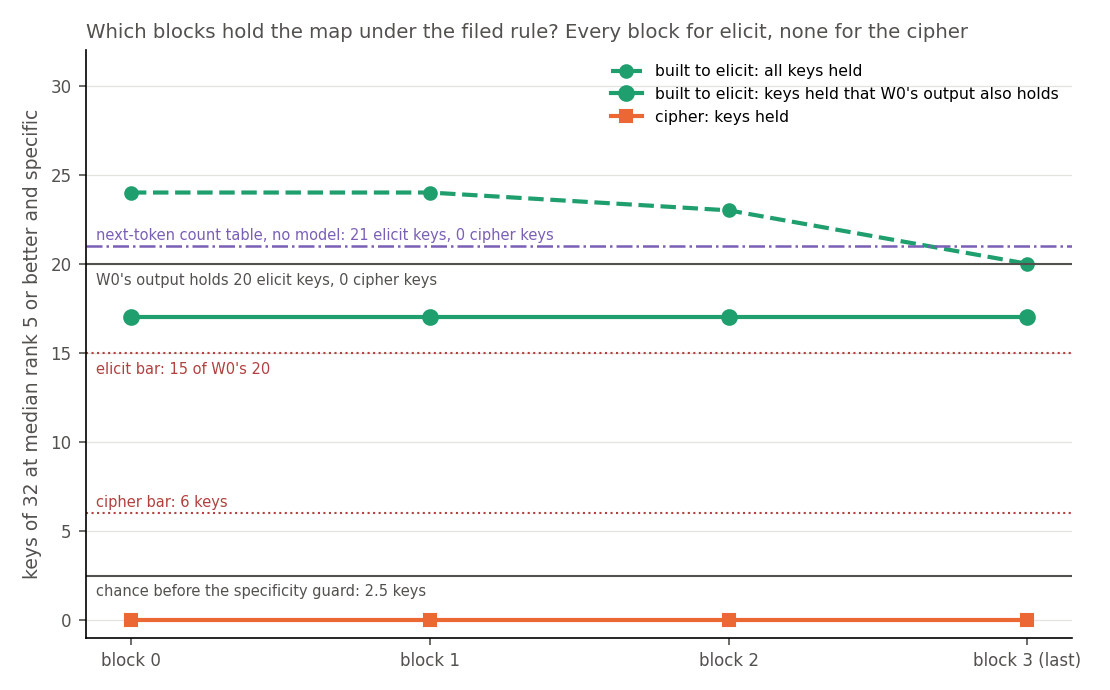

In [3]:
show("possession.png")


**Reading it.** Every block holds 17 of W0's 20 elicit keys, above the bar of 15, and no block holds a cipher key. The surprise is block 0, which holds as many of them as the last block and more keys in all. The filed rule says the map is held at the block nearest the input. The purple line is a table of counts with no model, taken up below.

### Does removing the row cost elicit fine-tunes more of their gain?


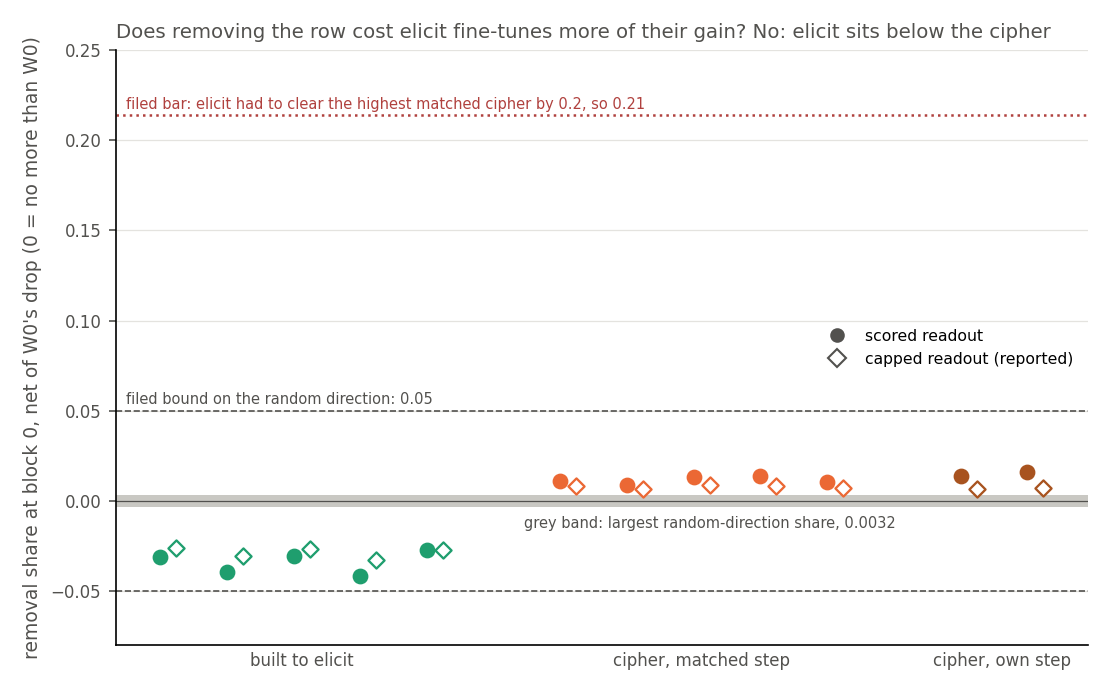

In [4]:
show("removal.png")


**Reading it.** No. Elicit shares run from -0.042 to -0.027 and cipher shares from 0.009 to 0.014, so elicit sits 0.045 below the cipher where the rule needed it 0.2 above. The capped readout reads the same way. Every share is small beside a gain of about 11 in log-odds.

### What does the removal actually do?


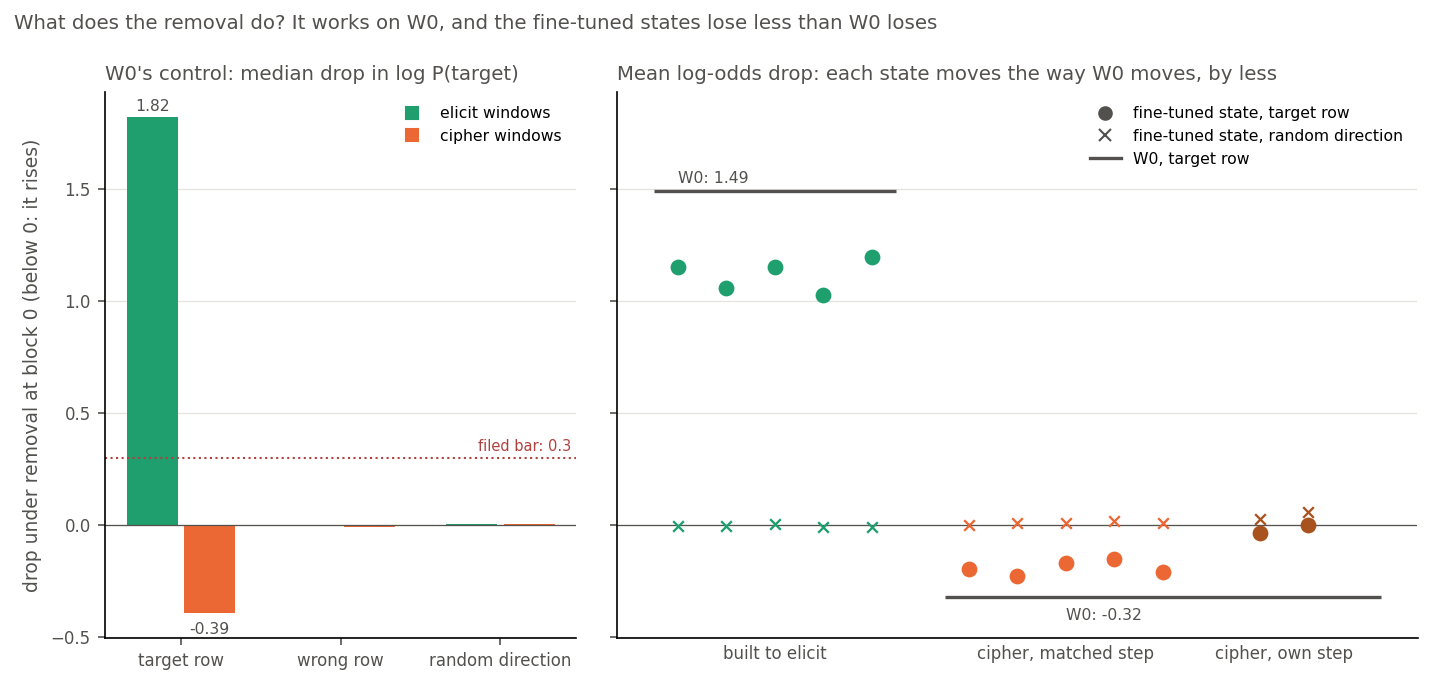

In [5]:
show("drops.png")


**Reading it.** It works on W0 and costs the states less than W0. On W0, the target row takes 1.82 nats and a wrong row almost nothing, so the row matters and is specific to the value. On cipher windows the removal raises W0's answer, so the cipher arm has no positive control. Each state moves the way W0 moves, by less.

### Can one row take the gain away even at the output?


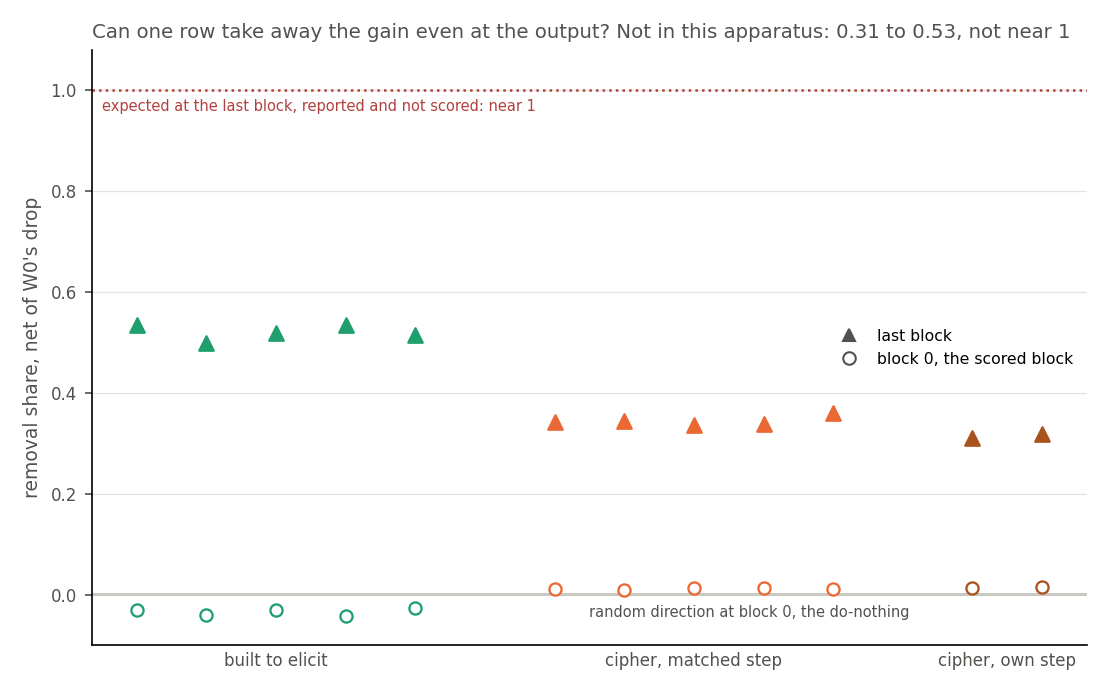

In [6]:
show("last_block.png")


**Reading it.** Not in this apparatus. The last-block removal was reported and expected near 1, and it reads 0.31 to 0.53. So a single row falls short of the whole gain even there, which limits what any share at block 0 can read. We did not measure the row's angle to the model's output head, so we cannot say why.

## Provisional readings, separate from the filed verdict

None of these was filed, none changes a verdict, and none is a tested cause.

### Is block 0's holding the prior tilt?


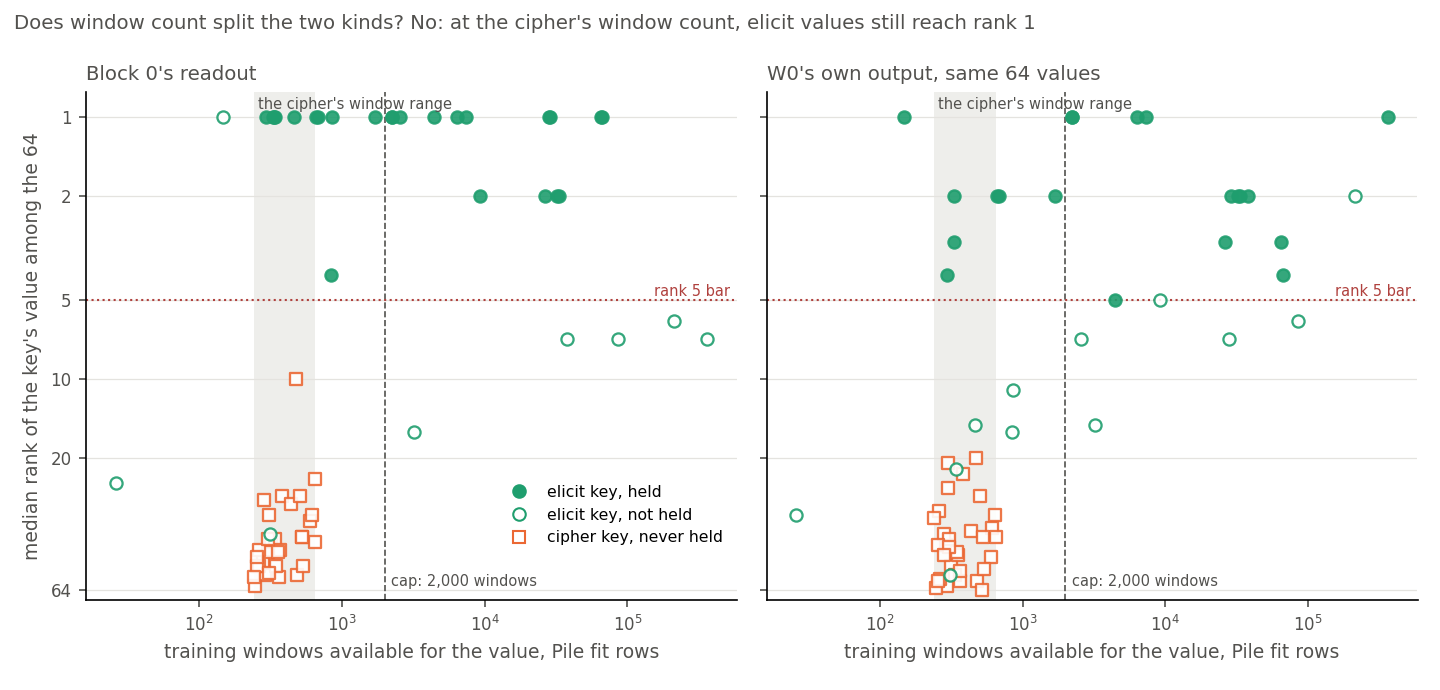

In [7]:
show("tilt.png")


**Reading it.** The tilt does not look sufficient, though the saved data cannot exclude it. Common elicit values train on up to 2,000 windows and cipher values on about 350. Yet six elicit values have window counts inside the cipher's range, and block 0 holds five of them at rank 1. It holds none of the 32 cipher keys. Moving W0's own prior by up to 5 nats moves the cipher's median rank by 1. Six keys is few.

### Could the training text alone give this pattern?


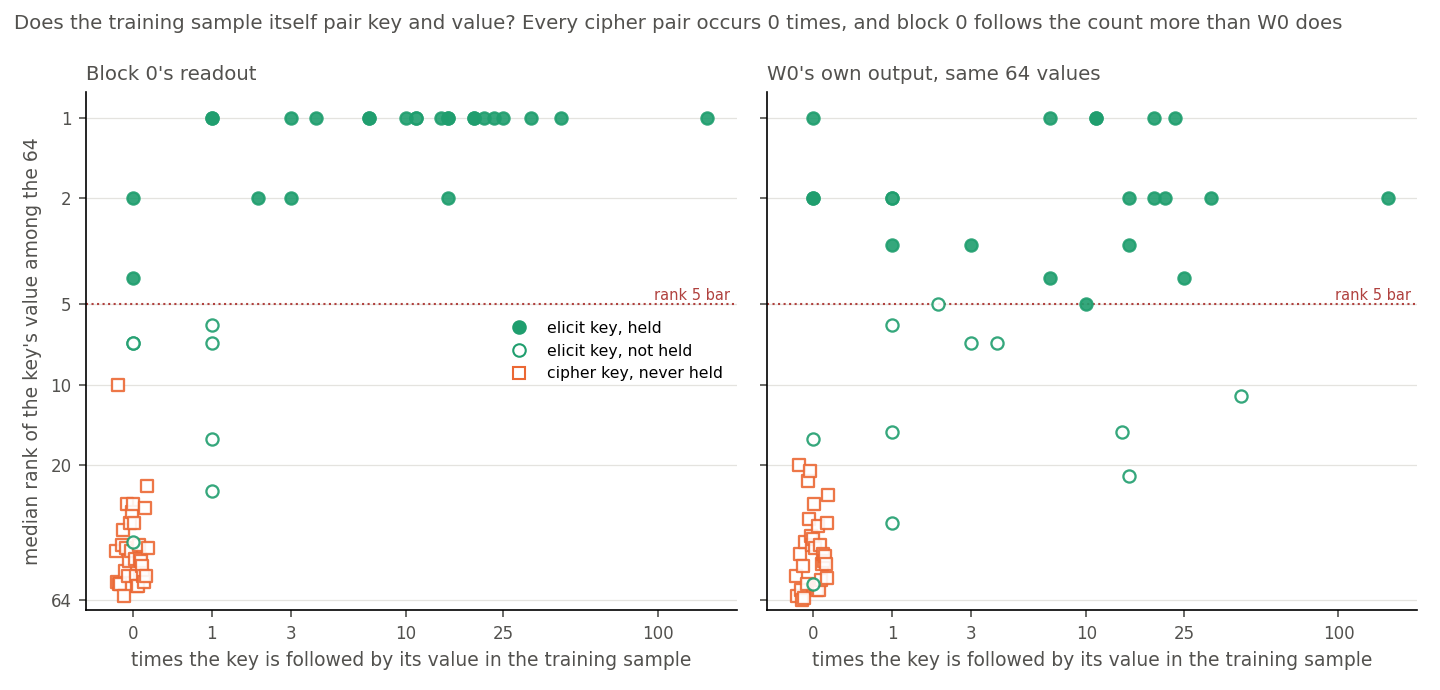

In [8]:
show("lookup.png")


**Reading it.** Nearly. The readout reads at the key token, so block 0 can see which token is there. We counted how often each key is directly followed by each value in the readout's training sample, with no model. Every cipher pair occurs zero times, while elicit pairs occur 459 times.

That smoothed table, put through the same rule, holds 21 elicit keys and no cipher key. It holds 15 of W0's 20, or 14 once the unfit key is dropped, against a bar of 15. Block 0's ranks follow the table's with a rank correlation of 0.86, and W0's output follows it at only 0.14. It is not only memorised pairs: of the five elicit pairs absent from the sample, block 0 still ranks two at 5 or better. So the filed clause passes, but holding at block 0 is weak evidence that W0 computes the map there. This counting was post-hoc and is no cause.

### What do the negative shares mean?

Removal costs an elicit state about 1.1 in log-odds where it costs W0 1.49, so the net is negative over a gain near 11. It does not mean removal helps the state, whose median probability barely moves. The largest random-direction share is 0.0032, so -0.03 is well outside that noise, and inside the filed bound of 0.05. Cipher states also respond with W0's sign and less size, so the opposite signs need not mean opposite things.

W0's control licenses one thing: on elicit windows the rows are not noise. It does not turn "unreadable" into "the gain avoids the row", because the fit bar missed. It also says nothing about cipher rows, or about blocks 1 and 2, where no removal ran.

### Why one minute against an estimated ten?

Every stage ran at its filed size: 57,345 fit windows, 7,617 held-out, 4,000 steps on each readout, and 36 removals on twelve states. The estimate came from upper bounds in the earlier readout experiment.


## What we learned

Under the filed rule this run does not say whether the pair's label is causal. Holding at block 0 is weak evidence, since a count table with no model comes close to the same pattern. Removing the row costs the states less than W0 on both kinds and both readouts. So r's reading of this pair still lacks the causal check that `decisions.md` row 112 asks for.

## How compelling is the evidence

One readout seed, one key draw, one model, about 3 windows per key and 48 scoring windows per state. The removal ran at one block and one position. Holding is blind to non-linear encodings, directions the model does not read and the training prior, and we found it is also blind to one-token co-occurrence. The removal share is blind to a route that re-encodes the value off the row. Its controls read: W0 passes, the random direction passes, the last block misses its expected value. The holding metric bears on the claim about where the values sit, and the share on the claim about the gain.

## Surprises

**Something unexpected happened that I cannot explain.** We predicted elicit shares at least 0.2 above cipher shares, and they sit 0.045 below them on both readouts. The rule reads this as no separation. Also unexplained: block 0 matching the last block, the last-block removal far from 1, and the removal raising W0's answer on cipher windows. The fit bar missed narrowly, by 0.08 nats.

## What next

The filed tree stops here and tells the user; these are not re-readings of this run.

1. **The user decides the line:** wait for the counting model's test, or go to the Qwen table.
2. **A free diagnostic, no training, reported only:** the saved capped readout through the holding rule, the prior taken out of the scored rows, and removal at blocks 1 and 2. If cipher keys become held, the tilt is back.
3. **A new experiment with its own filing:** a readout retrained without the pair windows. If block 0 loses most of its keys, its holding came from co-occurrence.

## Departures from the literature

- **Jain et al. 2024, Def 1.** Their vocabulary is a few hundred tokens and ours is 64 values, because the full-vocabulary readout could not be fitted. They draw fresh samples from pretraining, and we reuse up to 2,000 Pile positions per value about 7 times, with only partial balance. We read at the key token of task windows. Their paper gives no thresholds, so ours were filed before the run. They prune or fine-tune in reverse, and we remove the readout row.
- **Belrose et al. 2023.** E64's plan and filing do not cite it. As recalled and not re-read, the tuned lens matches the model's own output over the full vocabulary. Ours predicts Pile's next token over 64 values at one position.

## Scorecard

| id | claim in words | rule | read | verdict |
|---|---|---|---|---|
| P1 | elicit held at block 0-2, cipher nowhere | 3/4 of 20; cipher 6 keys | blocks 0-3 at 17; cipher none | pass, as filed |
| P2 | share separates elicit above cipher | gap at least 0.2 | gap -0.045 | fail, sign reversed |
| P3 | last block reproduces W0 | 3/4 of 20; cipher not held | 17; 0 | pass |
| fit | last block near W0 at sample's prior | within 0.1 | over by 0.176 | missed |
| branch | | filed tree | fit missed and P2 fail | **unreadable; tell the user** |

## Provenance

Report `reports/analyses/2026-11-02_analysis_e64-readout64.md`. Results `experiments/readout64/results/run.json`, job 48611, MATS debug, about 1 min, $0, code `fcb049f`, results `60f0aa9`. Post-hoc count table `experiments/readout64/bigram_check.py`. Figures from `experiments/readout64/plot.py`.

## Not run

- The capped readout through the holding rule, or the prior taken out of the scored rows.
- Removal at blocks 1 and 2.
- The residual's component along the row on W0 and the states, so the negative share has no tested cause.
- The row's angle to the output head at the last block.
- A readout trained without the pair windows.
- A second readout seed or key draw.
- r scored against this check.
